In [ ]:
!pip install pandas numpy matplotlib seaborn statsmodels scikit-learn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [2]:
from google.colab import files
uploaded = files.upload()

Saving upi_monthly.csv to upi_monthly.csv


In [3]:
import pandas as pd

df = pd.read_csv('upi_monthly.csv')

df.head()

,Date,Month,FY,Banks,VolumeMn,ValueCr
0,2016-04-01,April-2016,2016-17,21,0.00,0.00
1,2016-05-01,May-2016,2016-17,21,0.00,0.00
2,2016-06-01,June-2016,2016-17,21,0.00,0.00
3,2016-07-01,July-2016,2016-17,21,0.09,0.38
4,2016-08-01,August-2016,2016-17,21,0.09,3.09


In [5]:
df['Date'] = pd.to_datetime(df['Date'])

df = df.sort_values('Date')

df.set_index('Date', inplace=True)

df.head()

,Month,FY,Banks,VolumeMn,ValueCr
Date,,,,,
2016-04-01,April-2016,2016-17,21,0.00,0.00
2016-05-01,May-2016,2016-17,21,0.00,0.00
2016-06-01,June-2016,2016-17,21,0.00,0.00
2016-07-01,July-2016,2016-17,21,0.09,0.38
2016-08-01,August-2016,2016-17,21,0.09,3.09


In [6]:
print("Dataset Shape:", df.shape)

df.info()

print(df.isnull().sum())

print(df.describe())

Dataset Shape: (125, 5)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 125 entries, 2016-04-01 to 2026-08-01
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Month     125 non-null    object 
 1   FY        125 non-null    object 
 2   Banks     125 non-null    int64  
 3   VolumeMn  125 non-null    float64
 4   ValueCr   125 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 5.9+ KB
Month       0
FY          0
Banks       0
VolumeMn    0
ValueCr     0
dtype: int64
            Banks      VolumeMn       ValueCr
count  125.000000    125.000000  1.250000e+02
mean   314.256000   6767.498960  9.743877e+05
std    236.618275   7553.490458  9.941464e+05
min     21.000000      0.000000  0.000000e+00
25%    128.000000    524.940000  8.223221e+04
50%    229.000000   2807.510000  5.473732e+05
75%    550.000000  12102.670000  1.827869e+06
max    752.000000  24508.960000  2.990424e+06


In [7]:
print("First 5 records:")
display(df.head())

print("Last 5 records:")
display(df.tail())

First 5 records:


,Month,FY,Banks,VolumeMn,ValueCr
Date,,,,,
2016-04-01,April-2016,2016-17,21,0.00,0.00
2016-05-01,May-2016,2016-17,21,0.00,0.00
2016-06-01,June-2016,2016-17,21,0.00,0.00
2016-07-01,July-2016,2016-17,21,0.09,0.38
2016-08-01,August-2016,2016-17,21,0.09,3.09


Last 5 records:


,Month,FY,Banks,VolumeMn,ValueCr
Date,,,,,
2026-04-01,April-2026,2026-27,713,22346.80,2902988.05
2026-05-01,May-2026,2026-27,720,23201.93,2990424.21
2026-06-01,June-2026,2026-27,731,22716.07,2892138.67
2026-07-01,July-2026,2026-27,741,23658.35,2987880.49
2026-08-01,August-2026,2026-27,752,24508.96,2982355.95


In [8]:
print("Starting Date:", df.index.min())
print("Ending Date:", df.index.max())

print("Number of observations:", len(df))

print("Date Frequency:")
print(pd.infer_freq(df.index))

Starting Date: 2016-04-01 00:00:00
Ending Date: 2026-08-01 00:00:00
Number of observations: 125
Date Frequency:
MS


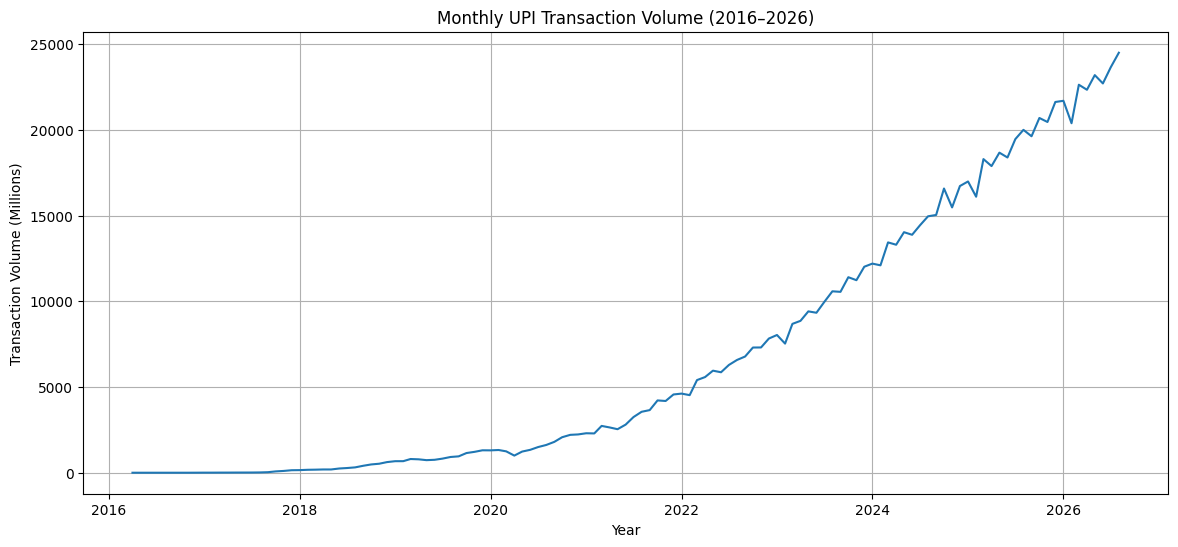

In [9]:
plt.figure(figsize=(14,6))

plt.plot(df.index, df['VolumeMn'])

plt.title('Monthly UPI Transaction Volume (2016–2026)')
plt.xlabel('Year')
plt.ylabel('Transaction Volume (Millions)')

plt.grid(True)
plt.show()

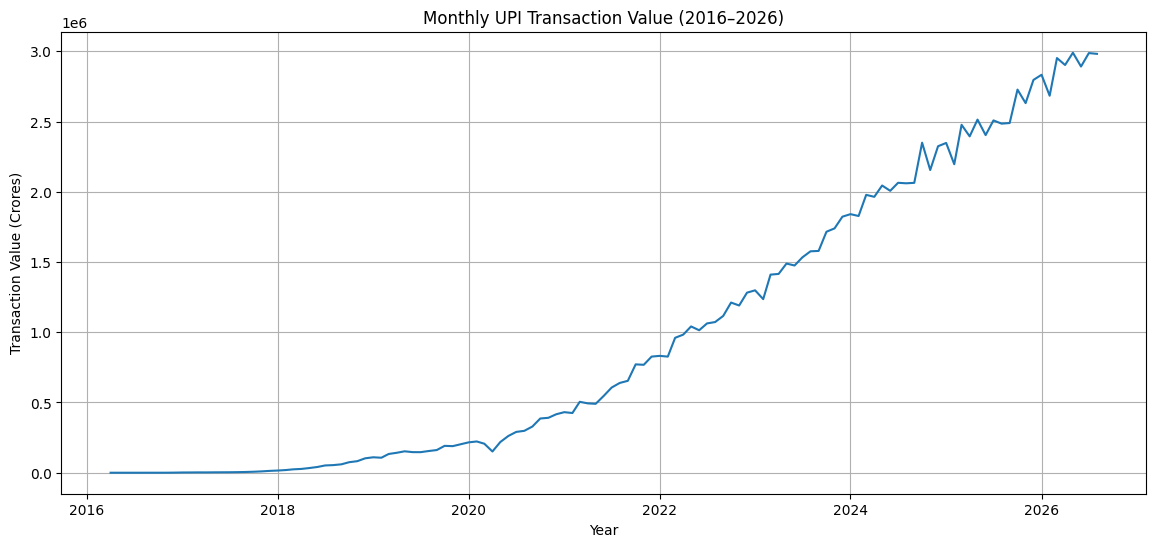

In [10]:
plt.figure(figsize=(14,6))

plt.plot(df.index, df['ValueCr'])

plt.title('Monthly UPI Transaction Value (2016–2026)')
plt.xlabel('Year')
plt.ylabel('Transaction Value (Crores)')

plt.grid(True)
plt.show()

In [11]:
df['MA_3'] = df['VolumeMn'].rolling(window=3).mean()

df['MA_6'] = df['VolumeMn'].rolling(window=6).mean()

df['MA_12'] = df['VolumeMn'].rolling(window=12).mean()

display(df[['VolumeMn', 'MA_3', 'MA_6', 'MA_12']].tail(15))

,VolumeMn,MA_3,MA_6,MA_12
Date,,,,
2025-06-01,18395.01,18321.963333,17728.265000,16633.911667
2025-07-01,19467.95,18846.806667,18140.256667,17053.278333
2025-08-01,20008.31,19290.423333,18790.610000,17473.716667
2025-09-01,19633.43,19703.230000,19012.596667,17856.356667
2025-10-01,20700.92,20114.220000,19480.513333,18199.352500
2025-11-01,20466.98,20267.110000,19778.766667,18614.765833
2025-12-01,21634.67,20934.190000,20318.710000,19023.487500
2026-01-01,21703.44,21268.363333,20691.291667,19415.774167
2026-02-01,20394.18,21244.096667,20755.603333,19773.106667


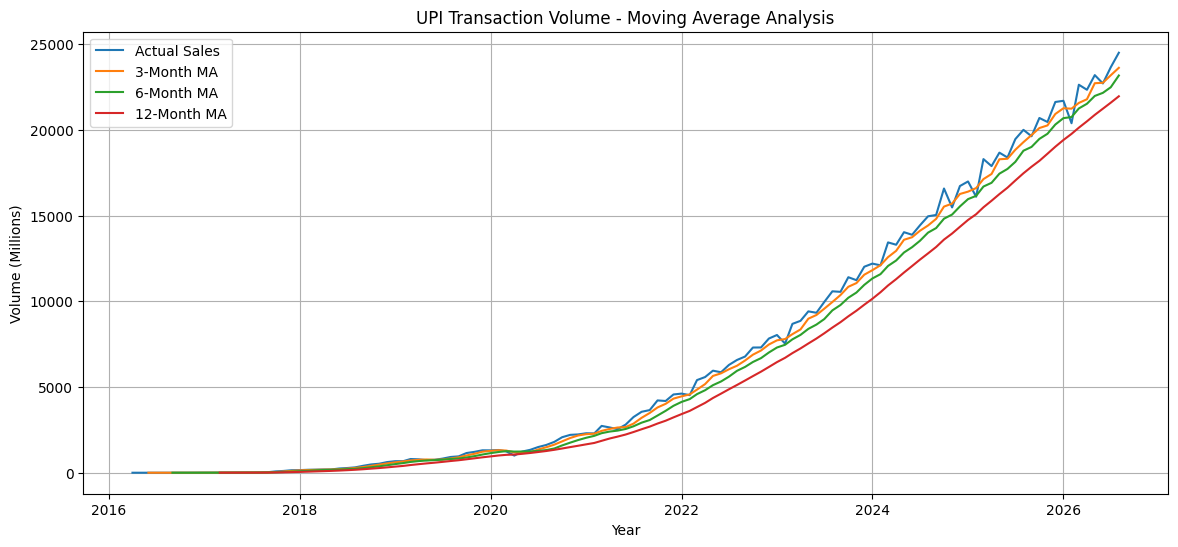

In [12]:
plt.figure(figsize=(14,6))

plt.plot(df.index, df['VolumeMn'], label='Actual Sales')

plt.plot(df.index, df['MA_3'], label='3-Month MA')

plt.plot(df.index, df['MA_6'], label='6-Month MA')

plt.plot(df.index, df['MA_12'], label='12-Month MA')

plt.title('UPI Transaction Volume - Moving Average Analysis')

plt.xlabel('Year')
plt.ylabel('Volume (Millions)')

plt.legend()
plt.grid(True)
plt.show()

In [13]:
print(df[df['VolumeMn'] == 0])

                 Month       FY  Banks  VolumeMn  ValueCr  MA_3  MA_6  MA_12
Date                                                                        
2016-04-01  April-2016  2016-17     21       0.0      0.0   NaN   NaN    NaN
2016-05-01    May-2016  2016-17     21       0.0      0.0   NaN   NaN    NaN
2016-06-01   June-2016  2016-17     21       0.0      0.0   0.0   NaN    NaN


In [14]:
#dickey_fuller_test

from statsmodels.tsa.stattools import adfuller

result = adfuller(df['VolumeMn'])

print("ADF Statistic:", result[0])
print("P-value:", result[1])
print("Critical Values:")

for key, value in result[4].items():
    print(key, ":", value)

if result[1] <= 0.05:
    print("\nThe data is Stationary")
else:
    print("\nThe data is Non-Stationary")

ADF Statistic: -1.3573334830009005
P-value: 0.602551586650216
Critical Values:
1% : -3.490683082754047
5% : -2.8879516565798817
10% : -2.5808574442009578

The data is Non-Stationary


/tmp/ipykernel_7275/990515796.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['VolumeMn'])


In [15]:
#differencing


df['Volume_Diff'] = df['VolumeMn'].diff()

# Remove the first NaN value
diff_data = df['Volume_Diff'].dropna()

print(diff_data.head(10))

Date
2016-05-01    0.00
2016-06-01    0.00
2016-07-01    0.09
2016-08-01    0.00
2016-09-01    0.00
2016-10-01    0.01
2016-11-01    0.19
2016-12-01    1.70
2017-01-01    2.47
2017-02-01   -0.08
Name: Volume_Diff, dtype: float64


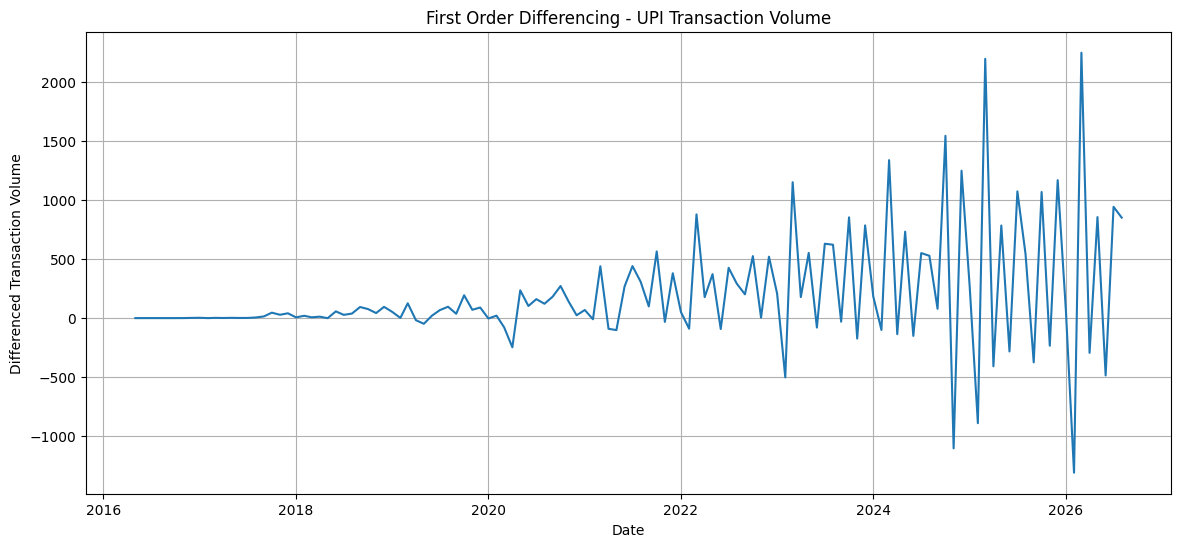

In [16]:
plt.figure(figsize=(14,6))

plt.plot(diff_data)

plt.title('First Order Differencing - UPI Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Differenced Transaction Volume')

plt.grid(True)
plt.show()

In [17]:
result_diff = adfuller(diff_data)

print("ADF Statistic:", result_diff[0])
print("P-value:", result_diff[1])

print("Critical Values:")

for key, value in result_diff[4].items():
    print(key, ":", value)

if result_diff[1] <= 0.05:
    print("\nThe differenced data is Stationary")
else:
    print("\nThe differenced data is Non-Stationary")

ADF Statistic: -0.7026540848074068
P-value: 0.8460608717967381
Critical Values:
1% : -3.4912451337340342
5% : -2.8881954545454547
10% : -2.5809876033057852

The differenced data is Non-Stationary


/tmp/ipykernel_7275/3078473523.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff = adfuller(diff_data)


In [18]:
# second-order differencing

second_diff = diff_data.diff().dropna()

print(second_diff.head(10))

Date
2016-06-01    0.00
2016-07-01    0.09
2016-08-01   -0.09
2016-09-01    0.00
2016-10-01    0.01
2016-11-01    0.18
2016-12-01    1.51
2017-01-01    0.77
2017-02-01   -2.55
2017-03-01    2.07
Name: Volume_Diff, dtype: float64


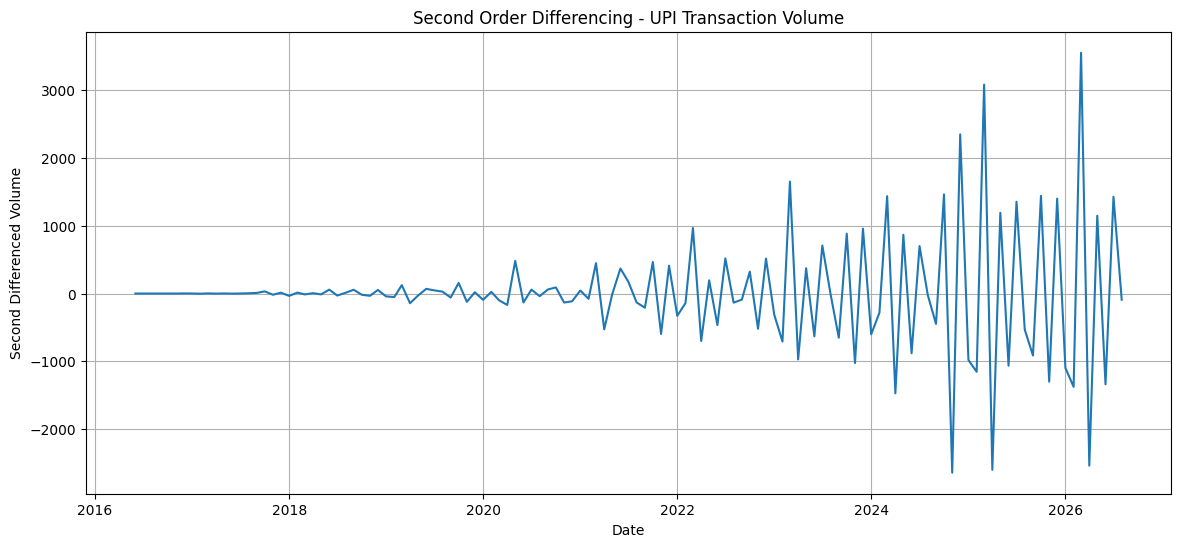

In [19]:
plt.figure(figsize=(14,6))

plt.plot(second_diff)

plt.title('Second Order Differencing - UPI Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Second Differenced Volume')

plt.grid(True)
plt.show()

In [20]:
result_second = adfuller(second_diff)

print("ADF Statistic:", result_second[0])
print("P-value:", result_second[1])

print("Critical Values:")

for key, value in result_second[4].items():
    print(key, ":", value)

if result_second[1] <= 0.05:
    print("\nThe second differenced data is Stationary")
else:
    print("\nThe second differenced data is Non-Stationary")

ADF Statistic: -6.331326576907221
P-value: 2.9014873583535292e-08
Critical Values:
1% : -3.4912451337340342
5% : -2.8881954545454547
10% : -2.5809876033057852

The second differenced data is Stationary


/tmp/ipykernel_7275/3726457519.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_second = adfuller(second_diff)


<Figure size 1200x500 with 0 Axes>

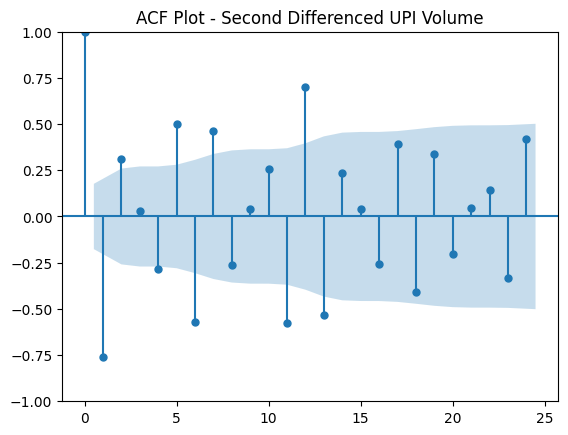

In [21]:
#acf
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12,5))

plot_acf(second_diff, lags=24)

plt.title('ACF Plot - Second Differenced UPI Volume')

plt.show()

<Figure size 1200x500 with 0 Axes>

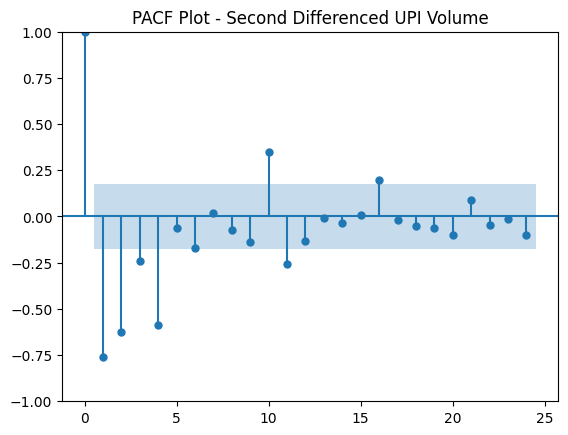

In [22]:
#pacf
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12,5))

plot_pacf(second_diff, lags=24, method='ywm')

plt.title('PACF Plot - Second Differenced UPI Volume')

plt.show()

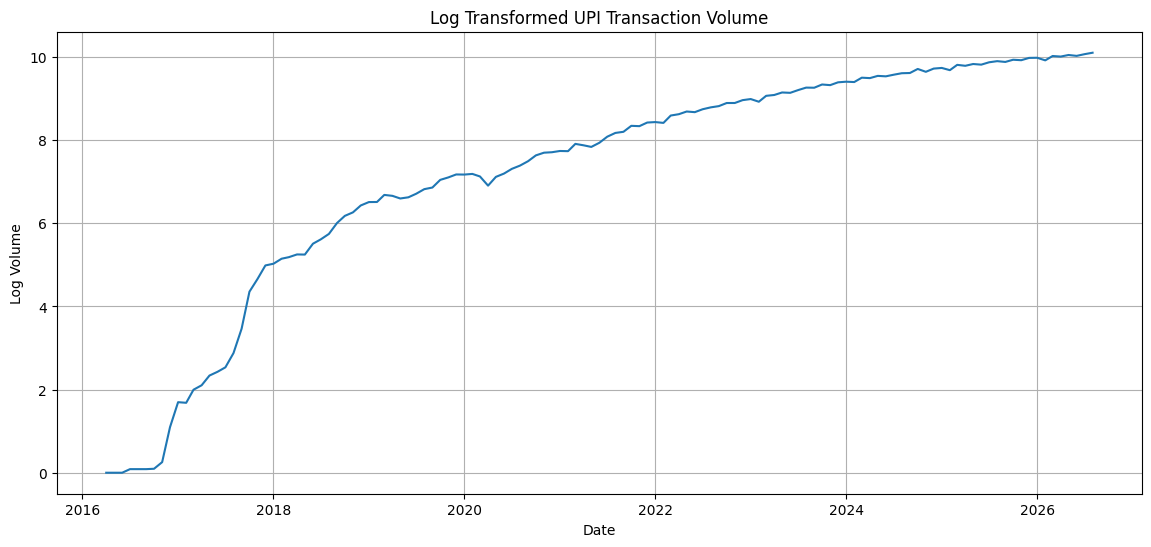

In [23]:
#log transformation

df['Log_Volume'] = np.log1p(df['VolumeMn'])

plt.figure(figsize=(14,6))

plt.plot(df.index, df['Log_Volume'])

plt.title('Log Transformed UPI Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Log Volume')

plt.grid(True)
plt.show()



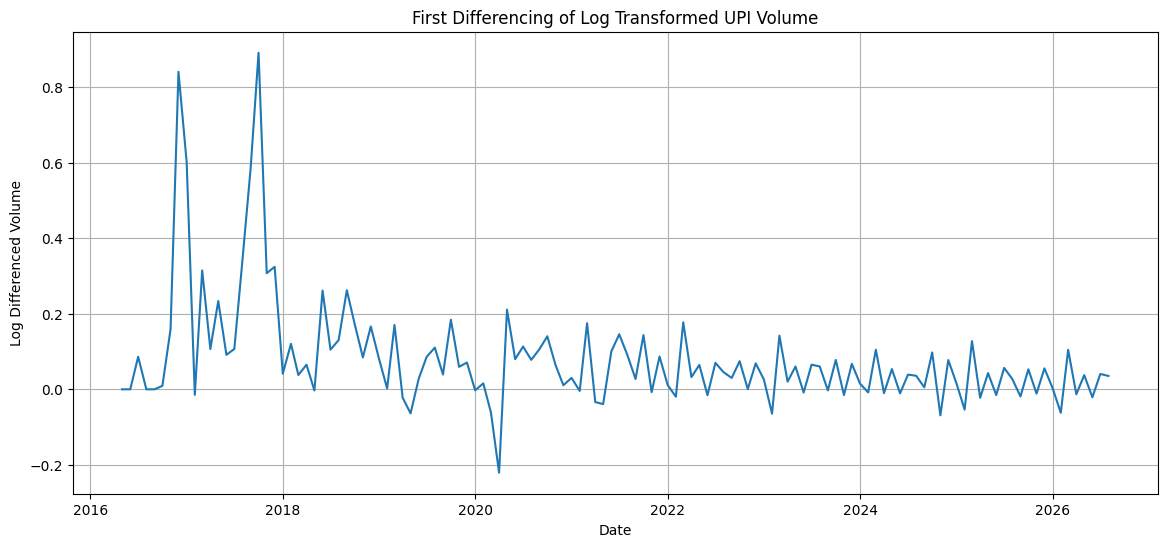

In [24]:
#First-order differencing of log data

log_diff = df['Log_Volume'].diff().dropna()

plt.figure(figsize=(14,6))

plt.plot(log_diff)

plt.title('First Differencing of Log Transformed UPI Volume')
plt.xlabel('Date')
plt.ylabel('Log Differenced Volume')

plt.grid(True)
plt.show()

In [25]:
#adf test

result_log = adfuller(log_diff)

print("ADF Statistic:", result_log[0])
print("P-value:", result_log[1])

print("Critical Values:")

for key, value in result_log[4].items():
    print(key, ":", value)

if result_log[1] <= 0.05:
    print("\nLog differenced data is Stationary")
else:
    print("\nLog differenced data is Non-Stationary")


ADF Statistic: -1.7698977028724805
P-value: 0.39550570259410434
Critical Values:
1% : -3.489589552580676
5% : -2.887477210140433
10% : -2.580604145195395

Log differenced data is Non-Stationary


/tmp/ipykernel_7275/54746531.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_log = adfuller(log_diff)


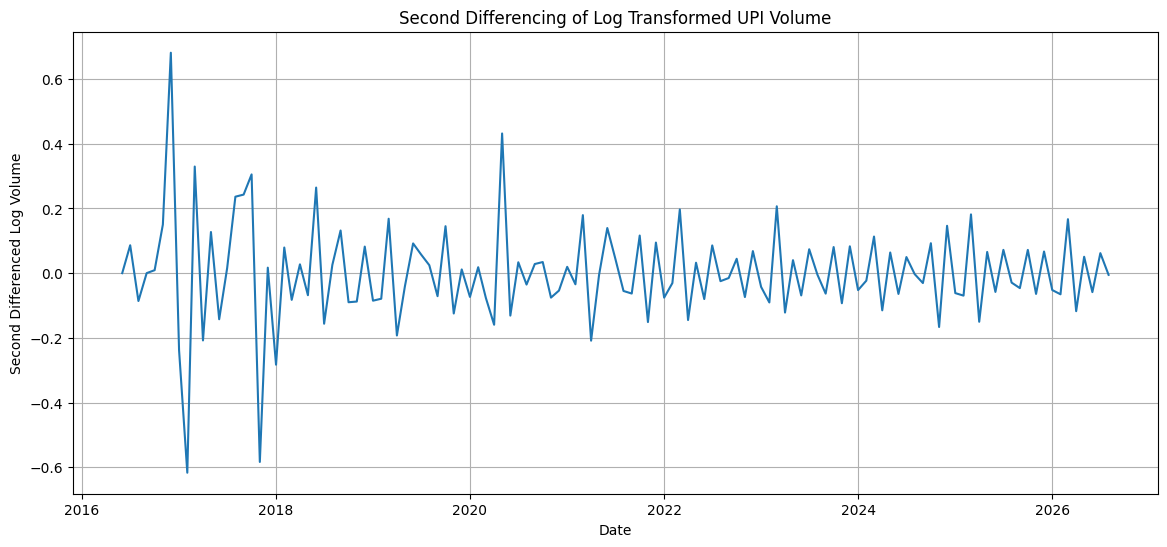

In [26]:
# Second-order differencing of log-transformed data

log_second_diff = log_diff.diff().dropna()

plt.figure(figsize=(14,6))

plt.plot(log_second_diff)

plt.title('Second Differencing of Log Transformed UPI Volume')
plt.xlabel('Date')
plt.ylabel('Second Differenced Log Volume')

plt.grid(True)
plt.show()

In [27]:
#adf test
result_log_second = adfuller(log_second_diff)

print("ADF Statistic:", result_log_second[0])
print("P-value:", result_log_second[1])

print("Critical Values:")

for key, value in result_log_second[4].items():
    print(key, ":", value)

if result_log_second[1] <= 0.05:
    print("\nSecond differenced log data is Stationary")
else:
    print("\nSecond differenced log data is Non-Stationary")

ADF Statistic: -5.240779935878554
P-value: 7.2541447670251425e-06
Critical Values:
1% : -3.489589552580676
5% : -2.887477210140433
10% : -2.580604145195395

Second differenced log data is Stationary


/tmp/ipykernel_7275/2076219381.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_log_second = adfuller(log_second_diff)


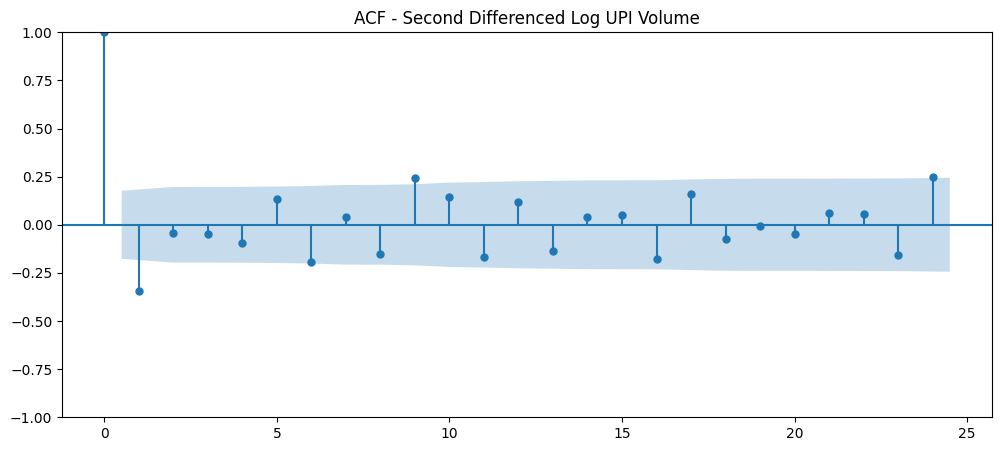

In [28]:
#acf plot

from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(log_second_diff, lags=24, ax=ax)

ax.set_title('ACF - Second Differenced Log UPI Volume')

plt.show()

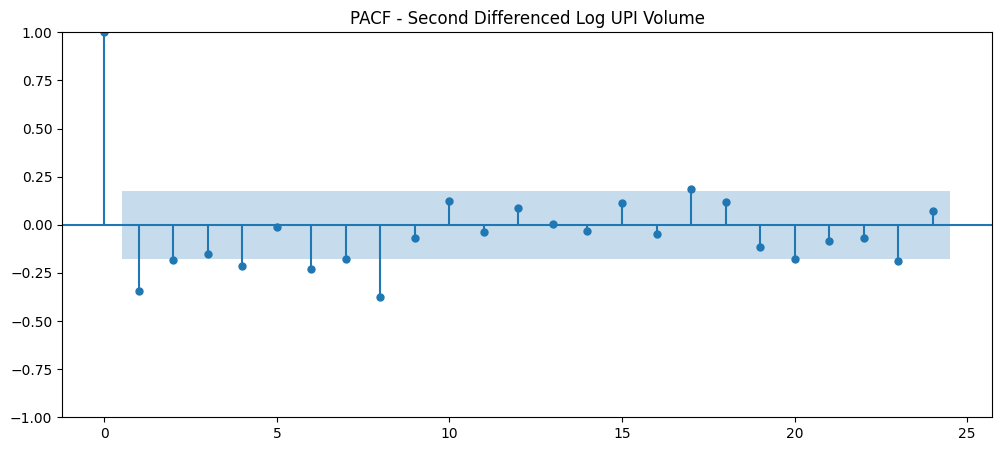

In [29]:
#pacf

from statsmodels.graphics.tsaplots import plot_pacf

fig, ax = plt.subplots(figsize=(12, 5))

plot_pacf(log_second_diff, lags=24,
          method='ywm', ax=ax)

ax.set_title('PACF - Second Differenced Log UPI Volume')

plt.show()

In [30]:
#ARIMA FORECASTING MODEL

# Prepare original log-transformed time series

ts = df['Log_Volume'].copy()

# Train-test split

train_size = int(len(ts) * 0.8)

train = ts.iloc[:train_size]

test = ts.iloc[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:", train.index.min(), "to", train.index.max())

print("Testing period:", test.index.min(), "to", test.index.max())



Training observations: 100
Testing observations: 25
Training period: 2016-04-01 00:00:00 to 2024-07-01 00:00:00
Testing period: 2024-08-01 00:00:00 to 2026-08-01 00:00:00


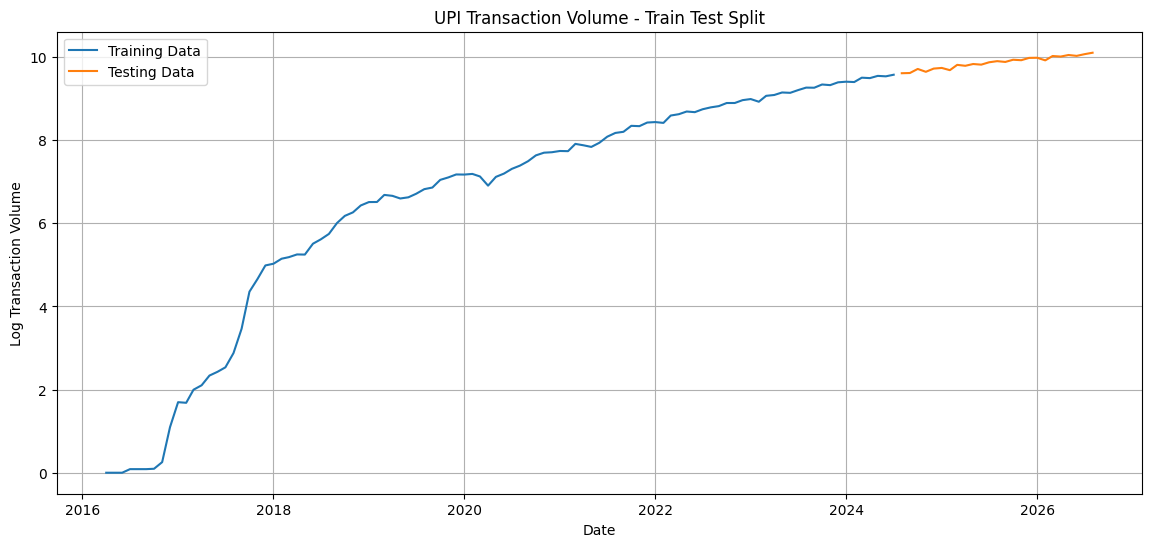

In [31]:
plt.figure(figsize=(14,6))

plt.plot(train, label='Training Data')

plt.plot(test, label='Testing Data')

plt.title('UPI Transaction Volume - Train Test Split')

plt.xlabel('Date')

plt.ylabel('Log Transaction Volume')

plt.legend()

plt.grid(True)

plt.show()

In [32]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(train, order=(1,2,1))

model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Log_Volume   No. Observations:                  100
Model:                 ARIMA(1, 2, 1)   Log Likelihood                  51.597
Date:                Sat, 07 Nov 2026   AIC                            -97.195
Time:                        07:04:51   BIC                            -89.440
Sample:                    04-01-2016   HQIC                           -94.058
                         - 07-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3850      0.088      4.365      0.000       0.212       0.558
ma.L1         -0.9386      0.062    -15.108      0.000      -1.060      -0.817
sigma2         0.0201      0.002     12.045      0.0

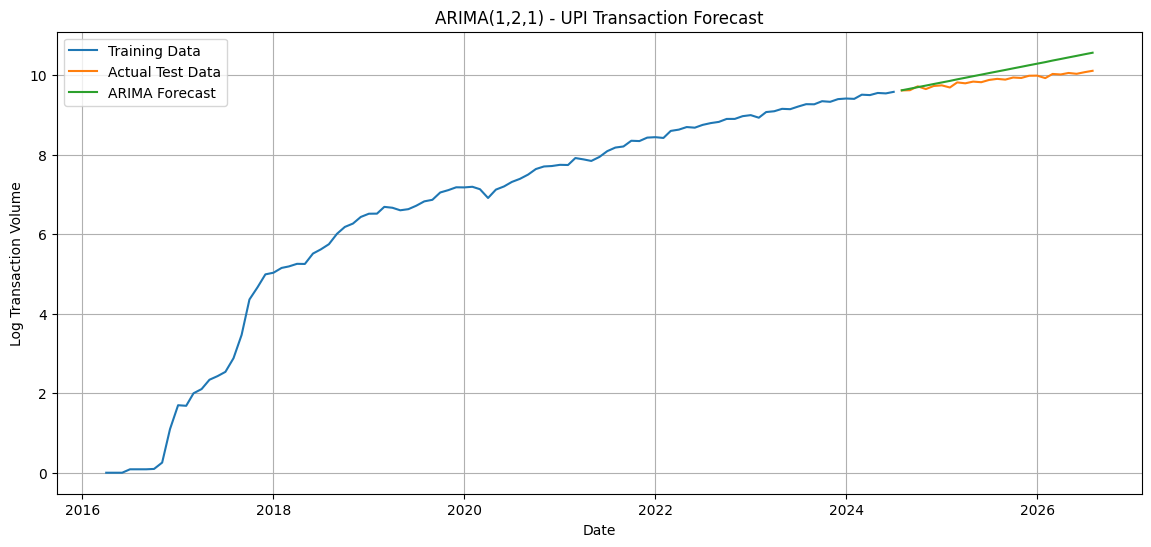

In [33]:
#Arima forecast

forecast = model_fit.forecast(steps=len(test))

plt.figure(figsize=(14,6))

plt.plot(train, label='Training Data')

plt.plot(test, label='Actual Test Data')

plt.plot(test.index, forecast, label='ARIMA Forecast')

plt.title('ARIMA(1,2,1) - UPI Transaction Forecast')

plt.xlabel('Date')
plt.ylabel('Log Transaction Volume')

plt.legend()
plt.grid(True)

plt.show()

In [34]:
#model evaluation

import numpy as np
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

actual_original = np.expm1(test)
forecast_original = np.expm1(forecast)

mae = mean_absolute_error(
    actual_original, forecast_original
)

rmse = np.sqrt(mean_squared_error(
    actual_original, forecast_original
))

mape = np.mean(
    np.abs((actual_original - forecast_original)
    / actual_original)
) * 100

print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MAE: 5554.083539880032
RMSE: 7061.401660068614
MAPE: 26.05139762984682 %


In [35]:
#multiple models

import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Candidate ARIMA models
orders = [
    (1, 2, 1),
    (2, 2, 1),
    (3, 2, 1),
    (1, 2, 2),
    (2, 2, 2)
]

results = []

# Convert actual test values to original scale
actual_original = np.expm1(test)

for order in orders:

    try:
        model = ARIMA(train, order=order)
        fitted_model = model.fit()

        predictions = fitted_model.forecast(
            steps=len(test)
        )

        forecast_original = np.expm1(predictions)

        mae = mean_absolute_error(
            actual_original,
            forecast_original
        )

        rmse = np.sqrt(mean_squared_error(
            actual_original,
            forecast_original
        ))

        mape = np.mean(
            np.abs(
                (actual_original - forecast_original)
                / actual_original
            )
        ) * 100

        results.append({
            'Model': f'ARIMA{order}',
            'AIC': fitted_model.aic,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape
        })

    except Exception as e:
        print(f"Model {order} failed:", e)

# Create comparison table
comparison = pd.DataFrame(results)

comparison = comparison.sort_values(
    by='MAPE'
)

print(comparison.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

         Model        AIC         MAE        RMSE      MAPE
ARIMA(3, 2, 1) -93.575263 4849.784437 6163.634559 22.765791
ARIMA(1, 2, 1) -97.194858 5554.083540 7061.401660 26.051398
ARIMA(1, 2, 2) -95.198509 5610.315592 7135.639482 26.310877
ARIMA(2, 2, 1) -95.199772 5627.534485 7158.496675 26.390196
ARIMA(2, 2, 2) -94.790384 6156.671953 7728.701656 28.982611


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [36]:
#Validate ARIMA

#refit

best_model = ARIMA(train, order=(3,2,1))

best_fit = best_model.fit()

print(best_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Log_Volume   No. Observations:                  100
Model:                 ARIMA(3, 2, 1)   Log Likelihood                  51.788
Date:                Sat, 07 Nov 2026   AIC                            -93.575
Time:                        07:05:06   BIC                            -80.650
Sample:                    04-01-2016   HQIC                           -88.347
                         - 07-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3728      0.126      2.970      0.003       0.127       0.619
ar.L2          0.0225      0.095      0.236      0.814      -0.164       0.209
ar.L3         -0.0661      0.104     -0.635      0.5

In [38]:
print("Model Convergence:",
      best_fit.mle_retvals['converged'])

Model Convergence: True


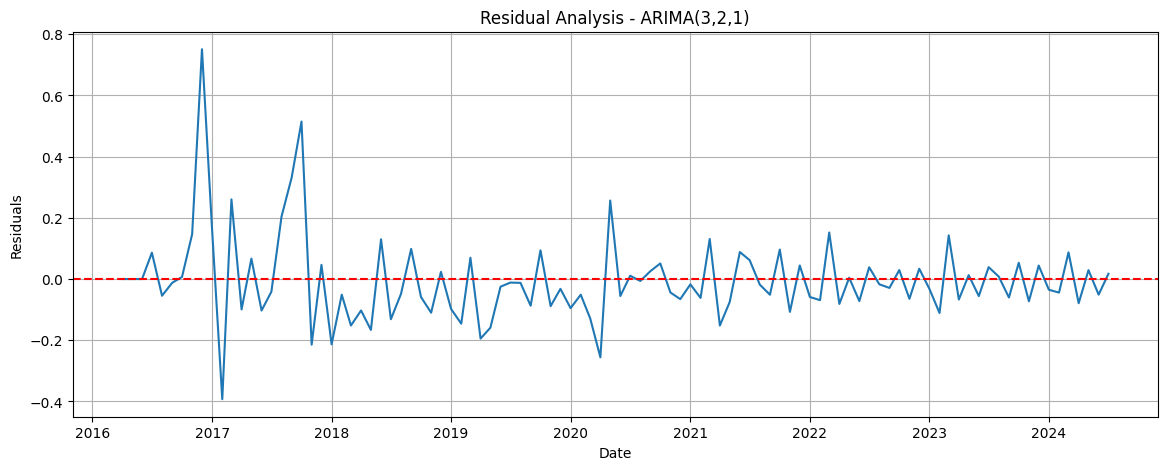

In [37]:
#residual analysis

residuals = best_fit.resid

plt.figure(figsize=(14,5))

plt.plot(residuals)

plt.title('Residual Analysis - ARIMA(3,2,1)')
plt.xlabel('Date')
plt.ylabel('Residuals')

plt.axhline(y=0, color='red', linestyle='--')

plt.grid(True)
plt.show()

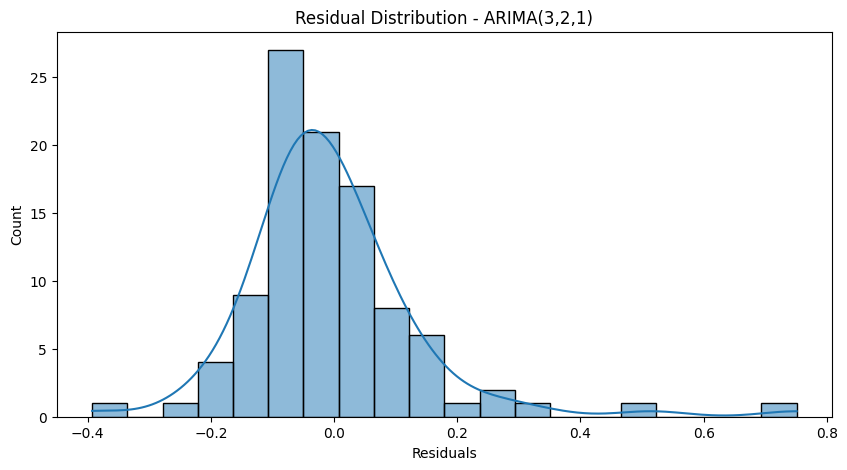

In [39]:
#residual dist

plt.figure(figsize=(10,5))

sns.histplot(residuals, kde=True)

plt.title('Residual Distribution - ARIMA(3,2,1)')
plt.xlabel('Residuals')

plt.show()

In [40]:
#Ljung-Box Test

from statsmodels.stats.diagnostic import acorr_ljungbox

lb_result = acorr_ljungbox(
    residuals,
    lags=[6, 12, 18],
    return_df=True
)

print("Ljung-Box Test Results:")
print(lb_result)

Ljung-Box Test Results:
      lb_stat  lb_pvalue
6    2.013983   0.918408
12  18.090489   0.112970
18  22.444732   0.212837


In [41]:
#ARIMA d=1

model_d1 = ARIMA(train, order=(1,1,1))

fit_d1 = model_d1.fit()

print(fit_d1.summary())

                               SARIMAX Results                                
Dep. Variable:             Log_Volume   No. Observations:                  100
Model:                 ARIMA(1, 1, 1)   Log Likelihood                  49.792
Date:                Sat, 07 Nov 2026   AIC                            -93.585
Time:                        07:05:21   BIC                            -85.799
Sample:                    04-01-2016   HQIC                           -90.435
                         - 07-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7929      0.094      8.458      0.000       0.609       0.977
ma.L1         -0.3145      0.153     -2.053      0.040      -0.615      -0.014
sigma2         0.0213      0.001     14.501      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


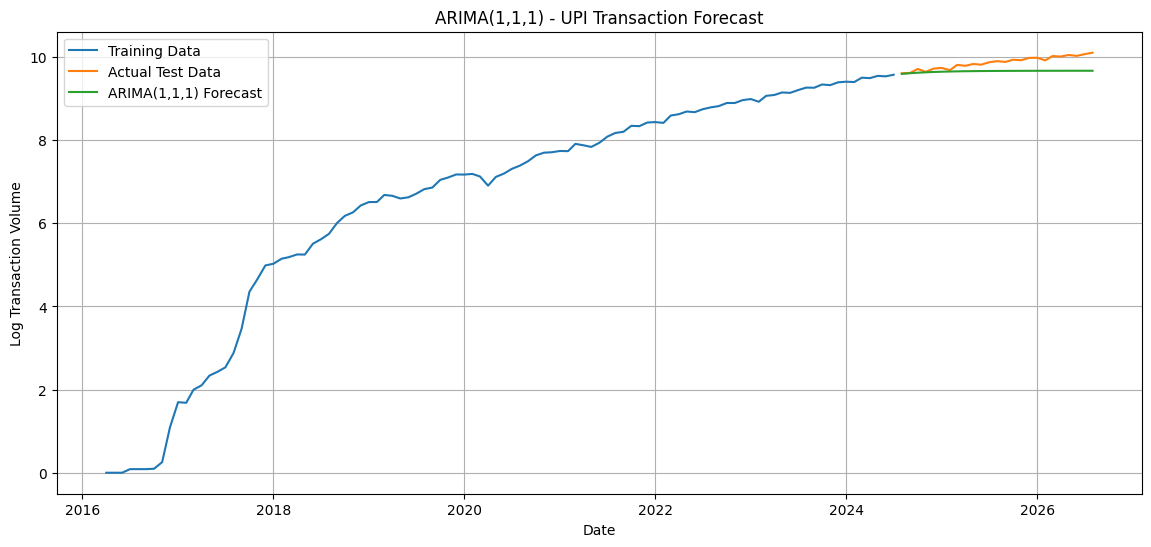

In [42]:
forecast_d1 = fit_d1.forecast(steps=len(test))

plt.figure(figsize=(14,6))

plt.plot(train, label='Training Data')
plt.plot(test, label='Actual Test Data')
plt.plot(test.index, forecast_d1, label='ARIMA(1,1,1) Forecast')

plt.title('ARIMA(1,1,1) - UPI Transaction Forecast')
plt.xlabel('Date')
plt.ylabel('Log Transaction Volume')

plt.legend()
plt.grid(True)
plt.show()

In [43]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual_original = np.expm1(test)
forecast_d1_original = np.expm1(forecast_d1)

mae_d1 = mean_absolute_error(
    actual_original,
    forecast_d1_original
)

rmse_d1 = np.sqrt(mean_squared_error(
    actual_original,
    forecast_d1_original
))

mape_d1 = np.mean(
    np.abs(
        (actual_original - forecast_d1_original)
        / actual_original
    )
) * 100

print("ARIMA(1,1,1) Results")
print("MAE:", mae_d1)
print("RMSE:", rmse_d1)
print("MAPE:", mape_d1, "%")

ARIMA(1,1,1) Results
MAE: 3870.249518261648
RMSE: 4626.434704188873
MAPE: 18.325925734333488 %


In [44]:
#ARIMA(1,1,1) residuals

residuals_d1 = fit_d1.resid

from statsmodels.stats.diagnostic import acorr_ljungbox

lb_d1 = acorr_ljungbox(
    residuals_d1,
    lags=[6, 12, 18],
    return_df=True
)

print("Ljung-Box Test - ARIMA(1,1,1)")
print(lb_d1)

Ljung-Box Test - ARIMA(1,1,1)
      lb_stat  lb_pvalue
6    5.432959   0.489596
12  24.160392   0.019343
18  27.910165   0.063436


In [45]:
#Test ARIMA(2,1,1)

model_211 = ARIMA(train, order=(2,1,1))

fit_211 = model_211.fit()

print(fit_211.summary())

                               SARIMAX Results                                
Dep. Variable:             Log_Volume   No. Observations:                  100
Model:                 ARIMA(2, 1, 1)   Log Likelihood                  52.495
Date:                Sat, 07 Nov 2026   AIC                            -96.990
Time:                        07:05:34   BIC                            -86.610
Sample:                    04-01-2016   HQIC                           -92.790
                         - 07-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3659      0.115     11.863      0.000       1.140       1.592
ar.L2         -0.3730      0.108     -3.458      0.001      -0.584      -0.162
ma.L1         -0.9238      0.080    -11.519      0.0

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


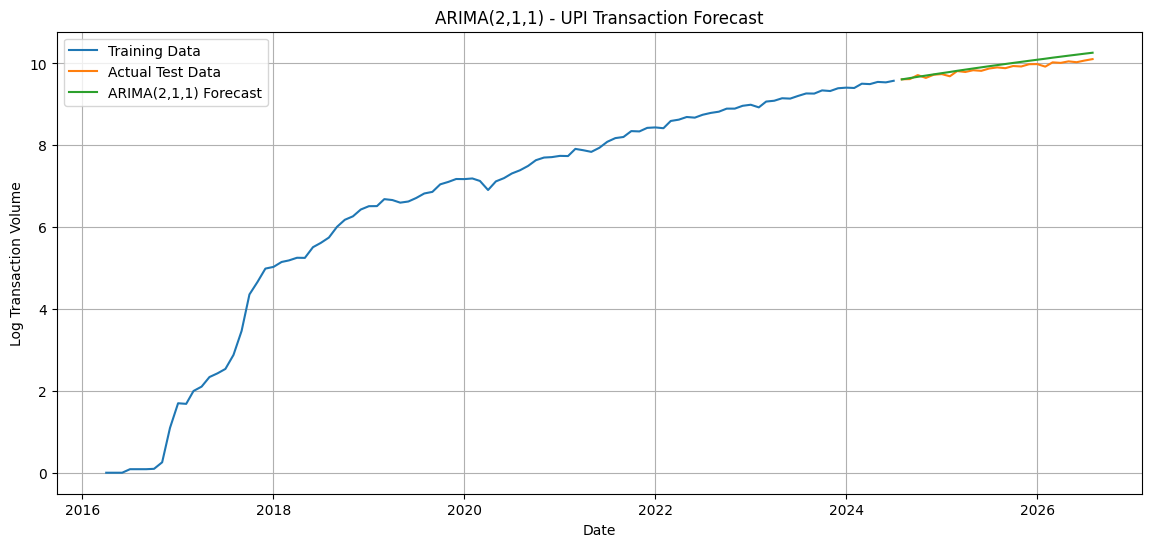

In [46]:
#ARIMA(2,1,1) forecast

forecast_211 = fit_211.forecast(steps=len(test))

plt.figure(figsize=(14,6))

plt.plot(train, label='Training Data')
plt.plot(test, label='Actual Test Data')
plt.plot(test.index, forecast_211,
         label='ARIMA(2,1,1) Forecast')

plt.title('ARIMA(2,1,1) - UPI Transaction Forecast')
plt.xlabel('Date')
plt.ylabel('Log Transaction Volume')

plt.legend()
plt.grid(True)
plt.show()

In [47]:
#evaluation metrics

actual_original = np.expm1(test)
forecast_211_original = np.expm1(forecast_211)

mae_211 = mean_absolute_error(
    actual_original,
    forecast_211_original
)

rmse_211 = np.sqrt(mean_squared_error(
    actual_original,
    forecast_211_original
))

mape_211 = np.mean(
    np.abs(
        (actual_original - forecast_211_original)
        / actual_original
    )
) * 100

print("ARIMA(2,1,1) Results")
print("MAE:", mae_211)
print("RMSE:", rmse_211)
print("MAPE:", mape_211, "%")

ARIMA(2,1,1) Results
MAE: 1921.7933368545948
RMSE: 2395.0836654201225
MAPE: 9.16631968123537 %


In [48]:
#model convergence

print("Model Convergence:",
      fit_211.mle_retvals['converged'])

Model Convergence: True


In [49]:
#AR and MA roots

print("AR Roots:")
print(fit_211.arroots)

print("\nAbsolute AR Roots:")
print(np.abs(fit_211.arroots))

print("\nMA Roots:")
print(fit_211.maroots)

print("\nAbsolute MA Roots:")
print(np.abs(fit_211.maroots))

AR Roots:
[1.01144589 2.6506651 ]

Absolute AR Roots:
[1.01144589 2.6506651 ]

MA Roots:
[1.08247425]

Absolute MA Roots:
[1.08247425]


In [50]:
#Ljung-Box test for ARIMA(2,1,1)

residuals_211 = fit_211.resid

lb_211 = acorr_ljungbox(
    residuals_211,
    lags=[6, 12, 18],
    return_df=True
)

print("Ljung-Box Test - ARIMA(2,1,1)")
print(lb_211)

Ljung-Box Test - ARIMA(2,1,1)
      lb_stat  lb_pvalue
6    2.728558   0.842063
12  19.484055   0.077497
18  23.848313   0.160060


In [51]:
#final comparison

final_comparison = pd.DataFrame({
    'Model': [
        'ARIMA(3,2,1)',
        'ARIMA(1,1,1)',
        'ARIMA(2,1,1)'
    ],
    'MAE': [
        4849.784437,
        mae_d1,
        mae_211
    ],
    'RMSE': [
        6163.634559,
        rmse_d1,
        rmse_211
    ],
    'MAPE': [
        22.765791,
        mape_d1,
        mape_211
    ]
})

print(final_comparison.to_string(index=False))

       Model         MAE        RMSE      MAPE
ARIMA(3,2,1) 4849.784437 6163.634559 22.765791
ARIMA(1,1,1) 3870.249518 4626.434704 18.325926
ARIMA(2,1,1) 1921.793337 2395.083665  9.166320


In [52]:
#final model using all available data

# Prepare the complete log-transformed series

final_ts = df['Log_Volume']

# Fit the selected ARIMA model

final_model = ARIMA(final_ts, order=(2,1,1))

final_fit = final_model.fit()

print(final_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:             Log_Volume   No. Observations:                  125
Model:                 ARIMA(2, 1, 1)   Log Likelihood                  76.543
Date:                Sat, 07 Nov 2026   AIC                           -145.086
Time:                        07:06:00   BIC                           -133.805
Sample:                    04-01-2016   HQIC                          -140.503
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3323      0.093     14.374      0.000       1.151       1.514
ar.L2         -0.3391      0.088     -3.874      0.000      -0.511      -0.168
ma.L1         -0.9214      0.064    -14.475      0.0

In [53]:
#6 month forecast

# Forecast the next 6 months
future_forecast_log = final_fit.forecast(steps=6)

# Convert predictions back to the original scale
future_forecast = np.expm1(future_forecast_log)

# Generate future month dates
future_dates = pd.date_range(
    start=final_ts.index[-1] + pd.offsets.MonthBegin(1),
    periods=6,
    freq='MS'
)

# Create forecast table
forecast_df = pd.DataFrame({
    'Forecasted_Volume_Mn': future_forecast.values
}, index=future_dates)

forecast_df.index.name = 'Date'

print(forecast_df.round(2))

            Forecasted_Volume_Mn
Date                            
2026-09-01              25134.47
2026-10-01              25683.20
2026-11-01              26208.00
2026-12-01              26727.42
2027-01-01              27247.93
2027-02-01              27771.74


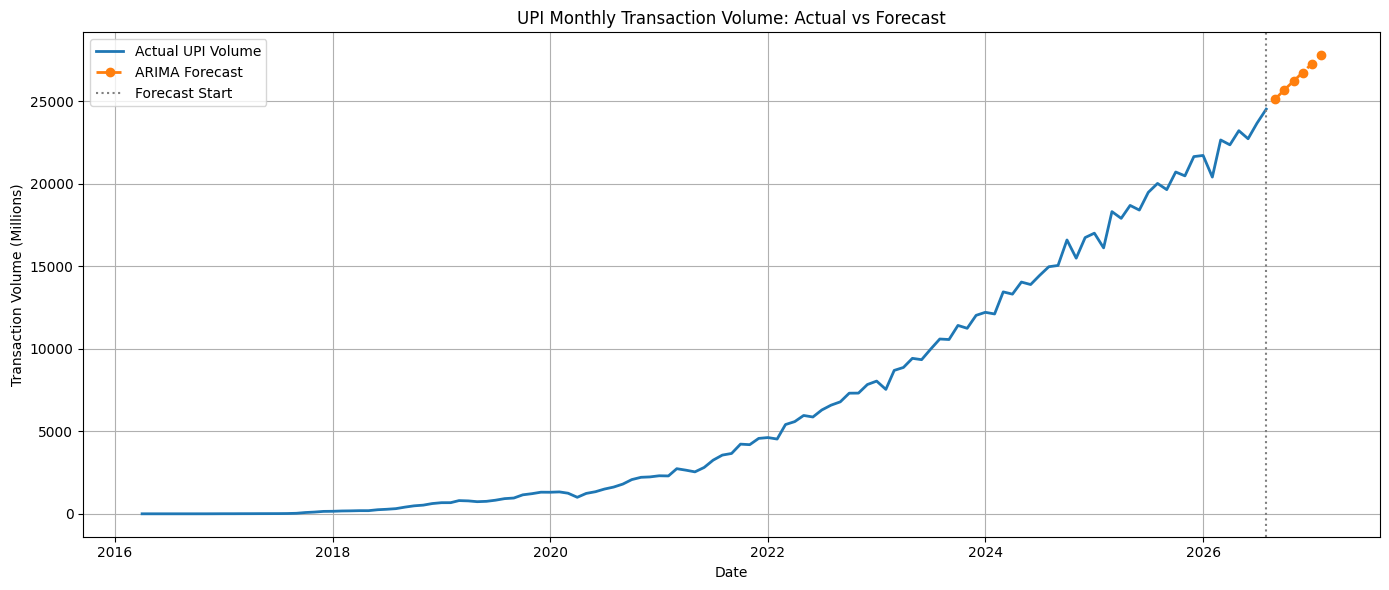

In [54]:
#plotting actual data and forecast data

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Historical actual data
plt.plot(
    df.index,
    df['VolumeMn'],
    label='Actual UPI Volume',
    linewidth=2
)

# Forecasted data
plt.plot(
    forecast_df.index,
    forecast_df['Forecasted_Volume_Mn'],
    label='ARIMA Forecast',
    linestyle='--',
    marker='o',
    linewidth=2
)

# Mark the beginning of the forecast
plt.axvline(
    x=df.index[-1],
    color='gray',
    linestyle=':',
    label='Forecast Start'
)

plt.title('UPI Monthly Transaction Volume: Actual vs Forecast')
plt.xlabel('Date')
plt.ylabel('Transaction Volume (Millions)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [55]:
# Calculate forecast growth
first_forecast = forecast_df['Forecasted_Volume_Mn'].iloc[0]
last_forecast = forecast_df['Forecasted_Volume_Mn'].iloc[-1]

growth = ((last_forecast - first_forecast) / first_forecast) * 100

print("September 2026 Forecast:", round(first_forecast, 2), "million")
print("February 2027 Forecast:", round(last_forecast, 2), "million")
print("Forecast Growth:", round(growth, 2), "%")

September 2026 Forecast: 25134.47 million
February 2027 Forecast: 27771.74 million
Forecast Growth: 10.49 %


In [56]:
# Final comparison of ARIMA models

comparison = pd.DataFrame({
    'Model': ['ARIMA(3,2,1)', 'ARIMA(1,1,1)', 'ARIMA(2,1,1)'],
    'MAE': [4849.78, 3870.25, 1921.79],
    'RMSE': [6163.63, 4626.43, 2395.08],
    'MAPE (%)': [22.77, 18.33, 9.17]
})

print(comparison.to_string(index=False))

       Model     MAE    RMSE  MAPE (%)
ARIMA(3,2,1) 4849.78 6163.63     22.77
ARIMA(1,1,1) 3870.25 4626.43     18.33
ARIMA(2,1,1) 1921.79 2395.08      9.17


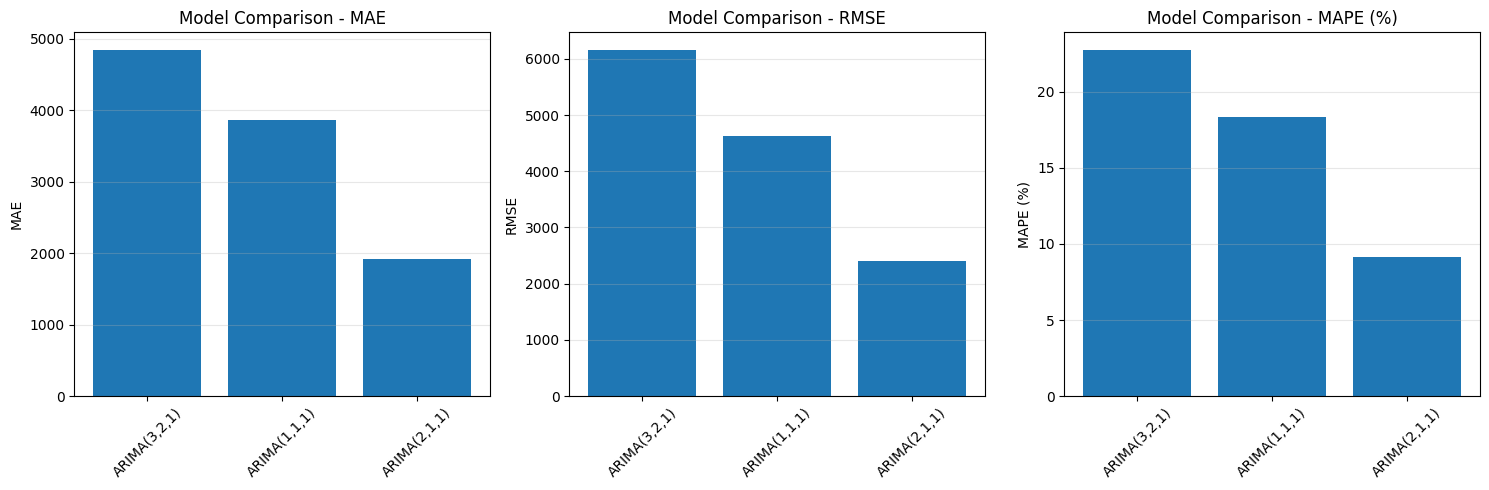

In [57]:
#model comparison chart

import matplotlib.pyplot as plt

metrics = ['MAE', 'RMSE', 'MAPE (%)']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, metric in enumerate(metrics):
    axes[i].bar(comparison['Model'], comparison[metric])
    axes[i].set_title(f'Model Comparison - {metric}')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
# Prepare the complete log-transformed series
final_ts = df['Log_Volume']

# Fit ARIMA(2,1,1) using all available observations
final_model = ARIMA(final_ts, order=(2, 1, 1))
final_fit = final_model.fit()

print("Final ARIMA(2,1,1) model fitted successfully!")
print(final_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Final ARIMA(2,1,1) model fitted successfully!
                               SARIMAX Results                                
Dep. Variable:             Log_Volume   No. Observations:                  125
Model:                 ARIMA(2, 1, 1)   Log Likelihood                  76.543
Date:                Sat, 07 Nov 2026   AIC                           -145.086
Time:                        07:06:24   BIC                           -133.805
Sample:                    04-01-2016   HQIC                          -140.503
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3323      0.093     14.374      0.000       1.151       1.514
ar.L2         -0.3391      0.088     -3.874      0.000      -0.511      -0.168
ma.L1 